# Comparing structural features to confidence scores

In [1]:
import re
import warnings
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm
from matplotlib import patches
from matplotlib.ticker import PercentFormatter
from statsmodels.regression.mixed_linear_model import MixedLMResults
from statsmodels.tools.sm_exceptions import ConvergenceWarning

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
entries = pd.read_csv('../data/interim/sequences_sample_1500.csv')

In [4]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [5]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
af3_structural_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_1500.csv')

structure_scores = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='name',
).merge(
    af3_structural_features,
    how='inner',
    left_on=['name', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

## Probabilities for structural features

In [6]:
structural_features = pd.read_csv('../data/processed/tcr_pmhc_structural_features.csv')
structural_features = structural_features.dropna()

mu=40.474007138087124, sigma=25.61220654046428


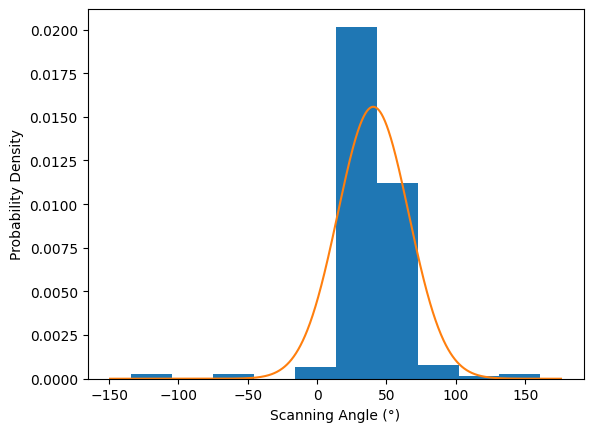

In [7]:
loc, scale = scipy.stats.norm.fit(structural_features['scanning_angle'])
print(f'mu={loc}, sigma={scale}')
scanning_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['scanning_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = scanning_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Scanning Angle (°)')
plt.ylabel('Probability Density')

plt.show()

In [8]:
structure_scores['scanning_angle_probability'] = structure_scores['scanning_angle'].apply(scanning_angle.pdf)

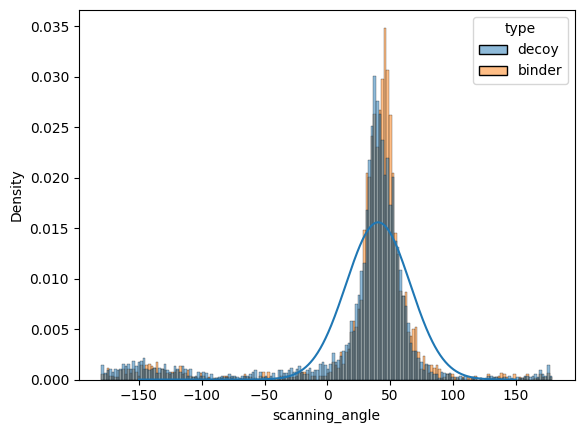

In [9]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(structure_scores, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

alpha=0.9339133223102127, x=0, theta=8.960068358179377


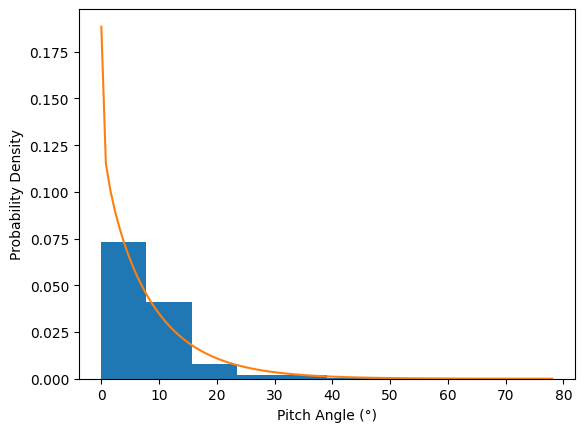

In [10]:
a, loc, scale = scipy.stats.gamma.fit(structural_features['pitch_angle'], floc=0)
print(f'alpha={a}, x={loc}, theta={scale}')
pitch_angle = scipy.stats.gamma(a=a, loc=loc, scale=scale)

ax = structural_features['pitch_angle'].plot.hist(density=True)

x = np.linspace(structural_features['pitch_angle'].min(), structural_features['pitch_angle'].max(), 100)
y = pitch_angle.pdf(x)

plt.plot(x, y, '-')


plt.xlabel('Pitch Angle (°)')
plt.ylabel('Probability Density')

plt.show()

In [11]:
structure_scores['pitch_angle_probability'] = structure_scores['pitch_angle'].apply(pitch_angle.pdf).replace(np.inf, 1)

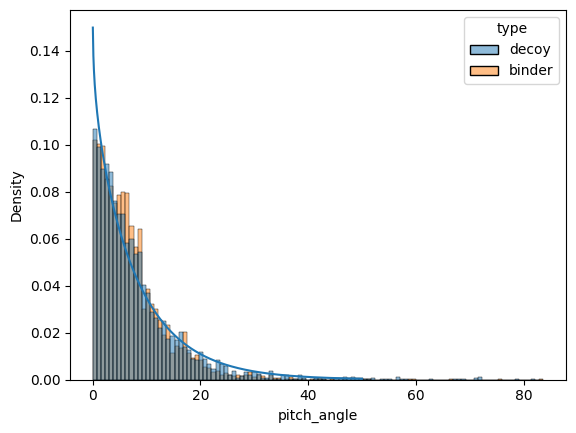

In [12]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(structure_scores, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

mu=-4.704773566307938, sigma=17.168889236280467


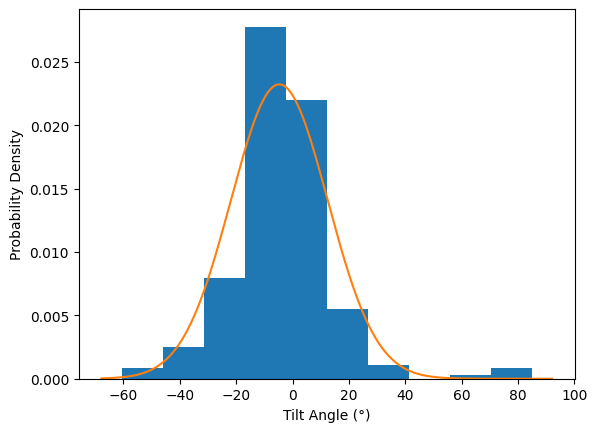

In [13]:
loc, scale = scipy.stats.norm.fit(structural_features['tilt_angle'])
print(f'mu={loc}, sigma={scale}')
tilt_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['tilt_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = tilt_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Tilt Angle (°)')
plt.ylabel('Probability Density')

plt.show()

In [14]:
structure_scores['tilt_angle_probability'] = structure_scores['tilt_angle'].apply(tilt_angle.pdf)

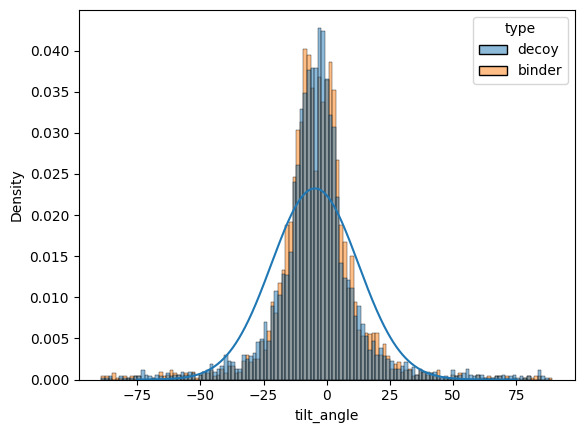

In [15]:
x = np.linspace(-75, 75, 1000)
plt.plot(x, tilt_angle.pdf(x))

sns.histplot(structure_scores, x='tilt_angle', hue='type', stat='density', common_norm=False)

plt.show()

mu=-5.888230488650083, sigma=18.718168379095623


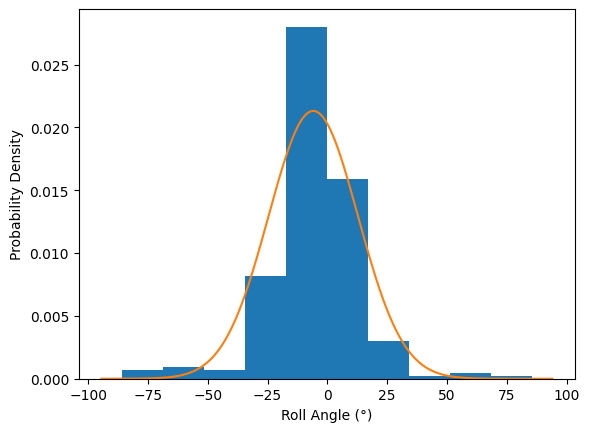

In [16]:
loc, scale = scipy.stats.norm.fit(structural_features['roll_angle'])
print(f'mu={loc}, sigma={scale}')
roll_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['roll_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = roll_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Roll Angle (°)')
plt.ylabel('Probability Density')

plt.show()

In [17]:
structure_scores['roll_angle_probability'] = structure_scores['roll_angle'].apply(roll_angle.pdf)

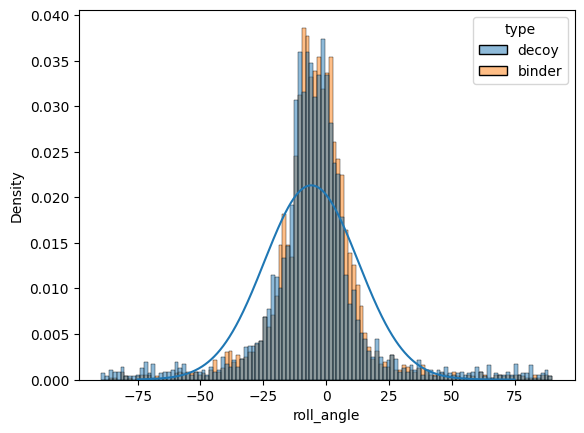

In [18]:
x = np.linspace(-75, 75, 1000)
plt.plot(x, roll_angle.pdf(x))

sns.histplot(structure_scores, x='roll_angle', hue='type', stat='density', common_norm=False)

plt.show()

mu=0.18027696760976686, sigma=3.398610347694314


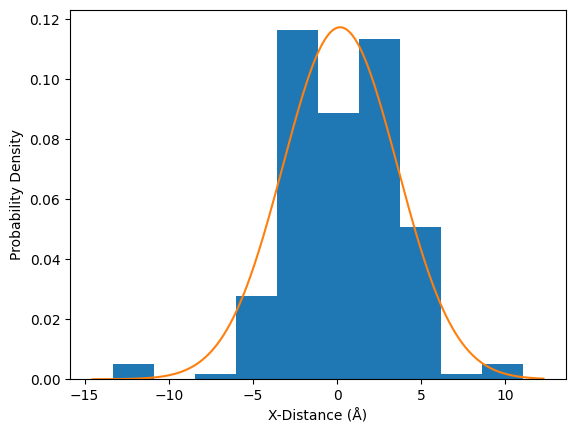

In [19]:
loc, scale = scipy.stats.norm.fit(structural_features['x_score'])
print(f'mu={loc}, sigma={scale}')
x_score = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['x_score'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = x_score.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('X-Distance (Å)')
plt.ylabel('Probability Density')

plt.show()

In [20]:
structure_scores['x_score_probability'] = structure_scores['x_score'].apply(x_score.pdf)

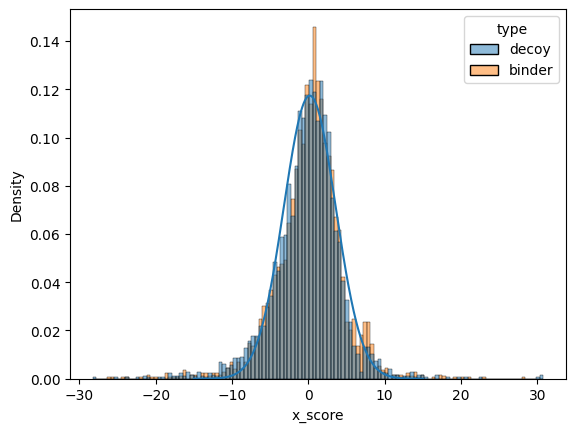

In [21]:
x = np.linspace(-15, 15, 1000)
plt.plot(x, x_score.pdf(x))

sns.histplot(structure_scores, x='x_score', hue='type', stat='density', common_norm=False)

plt.show()

mu=3.816825355321169, sigma=5.467852145913067


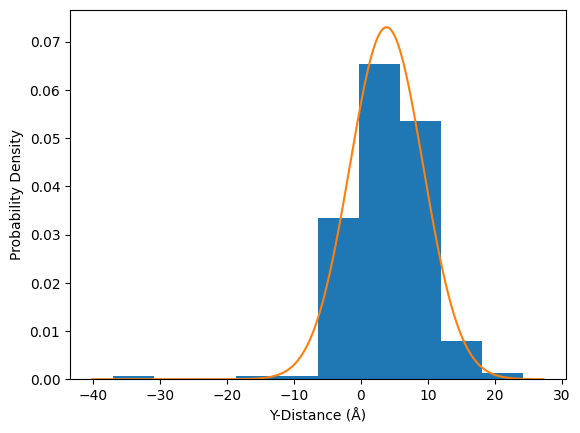

In [22]:
loc, scale = scipy.stats.norm.fit(structural_features['y_score'])
print(f'mu={loc}, sigma={scale}')
y_score = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['y_score'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = y_score.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Y-Distance (Å)')
plt.ylabel('Probability Density')

plt.show()

In [23]:
structure_scores['y_score_probability'] = structure_scores['y_score'].apply(y_score.pdf)

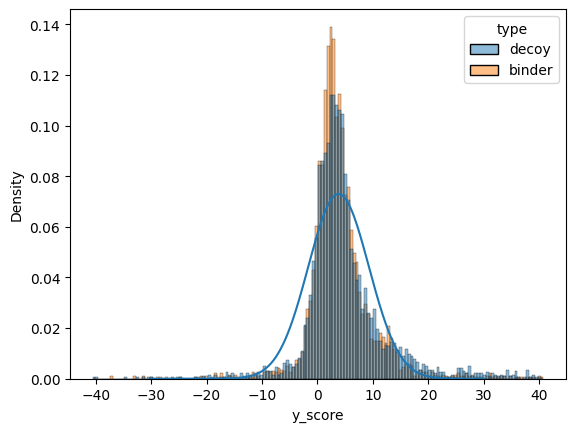

In [24]:
x = np.linspace(-30, 30, 1000)
plt.plot(x, y_score.pdf(x))

sns.histplot(structure_scores, x='y_score', hue='type', stat='density', common_norm=False)

plt.show()

In [25]:
def z_score(x: float | np.ndarray, means: np.ndarray, variances: np.ndarray, weights: np.ndarray) -> float | np.ndarray:
    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)

w=0.996, mu=27.896280916819133, sigma=1.3678096093630185
w=0.004000000000000009, mu=-11.793846130371067, sigma=0.001


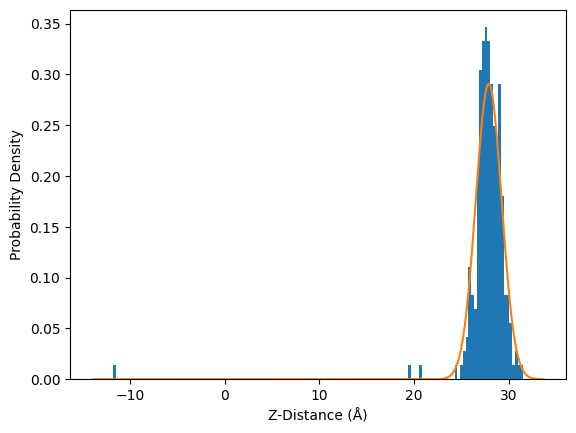

In [26]:
gmm = sklearn.mixture.GaussianMixture(n_components=2)
gmm.fit(structural_features['z_score'].to_numpy().reshape(-1, 1))

for mu, var, w in zip(gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten(), strict=True):
    print(f'w={w}, mu={mu}, sigma={np.sqrt(var)}')

ax = structural_features['z_score'].plot.hist(bins=150, density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten())

plt.plot(x, y, '-')

plt.xlabel('Z-Distance (Å)')
plt.ylabel('Probability Density')

plt.show()

In [27]:
structure_scores['z_score_probability'] = structure_scores['z_score'].apply(
    z_score, means=gmm.means_.flatten(), variances=gmm.covariances_.flatten(), weights=gmm.weights_.flatten()
)

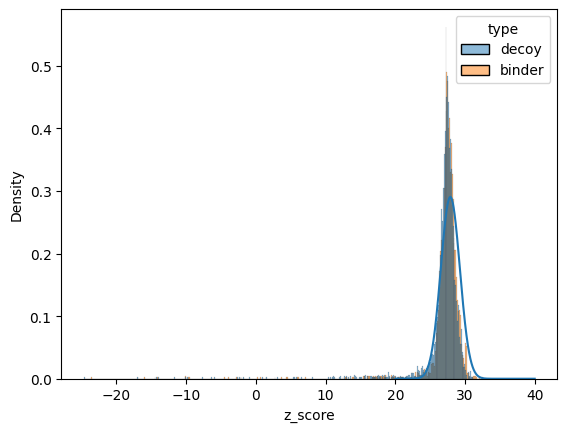

In [28]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten()))

sns.histplot(structure_scores, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [29]:
contact_probabilities = pd.read_csv('../data/processed/tcr_pmhc_contacts.csv')

contact_probabilities['proportion'] = contact_probabilities.groupby('mhc_type')['proportion'].transform(
    lambda group: group / group.sum()
)

contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_1500.csv')

contact_scores = (
    contact_maps.merge(
        contact_probabilities,
        how='left',
        on=[col for col in contact_probabilities if col != 'proportion'],
    )
    .groupby(['name', 'seed', 'sample'])['proportion']
    .aggregate(['sum', 'mean'])
)
contact_scores.columns = ['contact_map_probability_' + column_name for column_name in contact_scores.columns]

structure_scores = structure_scores.merge(
    contact_scores, how='left', left_on=['name', 'seed', 'sample'], right_index=True
)

<Axes: xlabel='score', ylabel='probability'>

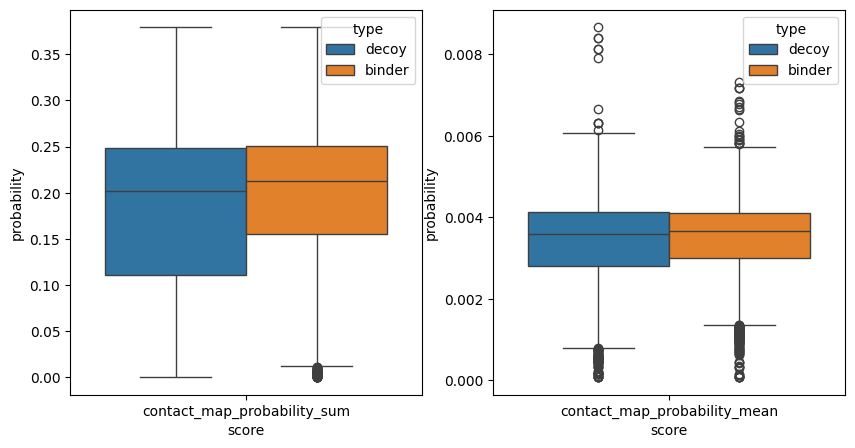

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_sum',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[0],
)

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_mean',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[1],
)

In [31]:
structure_scores['contact_map_probability'] = structure_scores['contact_map_probability_mean']

In [32]:
interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions.csv')

In [33]:
num_interactions = interactions.groupby('name').size()

mu=6.714859437751004, sigma=2.9035260960849754


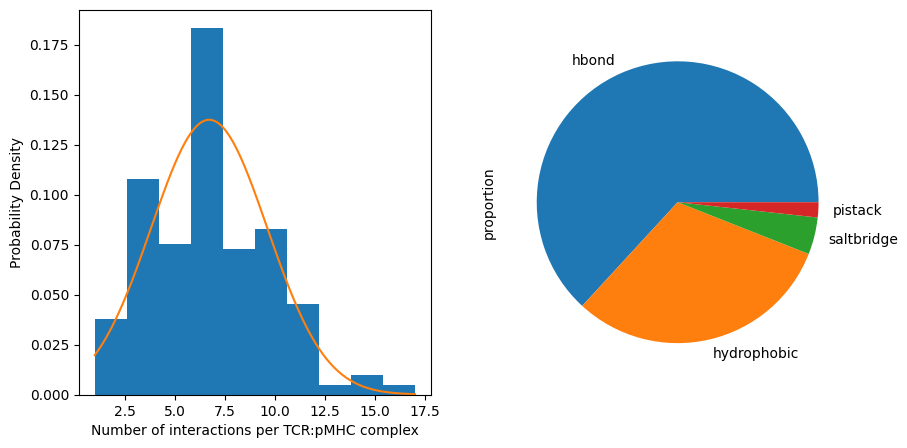

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

num_interactions.plot.hist(ax=axes[0], density=True)
x = np.linspace(num_interactions.min(), num_interactions.max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())

print(f'mu={num_interactions.mean()}, sigma={num_interactions.std()}')

axes[0].plot(x, y, '-')

axes[0].set_xlabel('Number of interactions per TCR:pMHC complex')
axes[0].set_ylabel('Probability Density')

interactions.value_counts('type', normalize=True).plot.pie(ax=axes[1])

plt.show()

In [35]:
interaction_types = interactions.value_counts(['type', 'name'])

hbond: a=3.2679950802320947, x=0, theta=1.3297691415242419
hydrophobic: a=3.939773260697842, x=0, theta=0.6035576229863059
pistack: a=3.5748642220000426, x=0, theta=0.47718801246856307
saltbridge: a=8.174962676909084, x=0, theta=0.16386896117499328


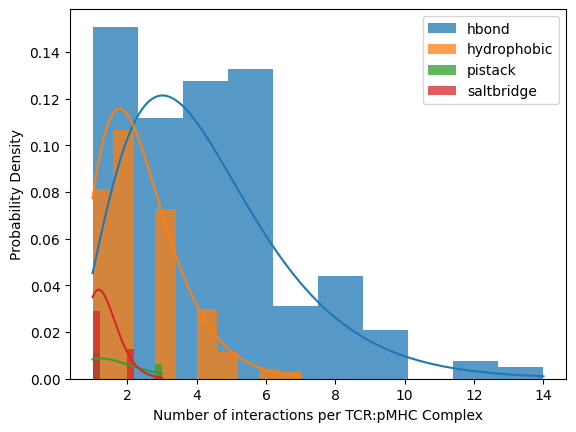

In [36]:
colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

total_count = interaction_types.sum()

interaction_types_parameters = {}

for i, (interaction_type, group) in enumerate(interaction_types.reset_index().groupby('type')):
    interaction_types_parameters[interaction_type] = {}

    colour = colours[i % len(colours)]

    count = group['count']
    group_count = count.sum()

    weight = group_count / total_count

    a, loc, scale = scipy.stats.gamma.fit(group['count'], floc=0)
    print(f'{interaction_type}: a={a}, x={loc}, theta={scale}')

    interaction_types_parameters[interaction_type]['weight'] = weight
    interaction_types_parameters[interaction_type]['a'] = a
    interaction_types_parameters[interaction_type]['loc'] = loc
    interaction_types_parameters[interaction_type]['scale'] = scale

    x = np.linspace(count.min(), count.max(), 1000)
    y = scipy.stats.gamma.pdf(x, a=a, loc=loc, scale=scale) * weight

    plt.plot(x, y, '-', color=colour)

    counts, bins = np.histogram(count)
    probabilities = (counts / counts.sum()) * weight

    plt.stairs(
        probabilities,
        bins,
        fill=True,
        color=colour,
        alpha=0.75,
        label=interaction_type,
    )

plt.legend()
plt.ylabel('Probability Density')
plt.xlabel('Number of interactions per TCR:pMHC Complex')

plt.show()

In [37]:
af3_interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_1500.csv')
af3_interactions = af3_interactions.merge(
    entries, how='left', left_on='name', right_on='index', suffixes=('_interaction', '')
)

ROC-AUC: 0.5430006459502296


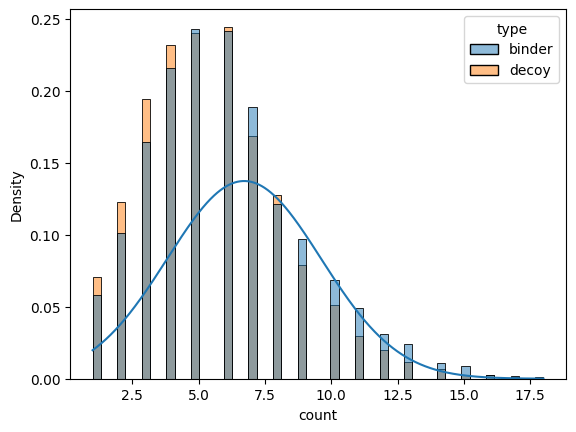

In [38]:
af3_interaction_counts = af3_interactions.groupby(['type', 'label', 'name', 'seed', 'sample']).size()
af3_interaction_counts.name = 'count'
af3_interaction_counts = af3_interaction_counts.reset_index()

sns.histplot(af3_interaction_counts, x='count', hue='type', stat='density')

x = np.linspace(af3_interaction_counts['count'].min(), af3_interaction_counts['count'].max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())
plt.plot(x, y, '-')

print('ROC-AUC:', sklearn.metrics.roc_auc_score(af3_interaction_counts['label'], af3_interaction_counts['count']))

plt.show()

In [39]:
af3_interaction_counts['num_interactions_probability'] = scipy.stats.norm.pdf(
    af3_interaction_counts['count'], loc=num_interactions.mean(), scale=num_interactions.std()
)
structure_scores = structure_scores.merge(
    af3_interaction_counts[['name', 'seed', 'sample', 'num_interactions_probability']],
    how='left',
    left_on=['name', 'seed', 'sample'],
    right_on=['name', 'seed', 'sample'],
)
structure_scores['num_interactions_probability'] = structure_scores['num_interactions_probability'].fillna(0.0)

hbond ROC-AUC: 0.5279766489583673
hydrophobic ROC-AUC: 0.5124630147994917
pistack ROC-AUC: 0.5272046925566344
saltbridge ROC-AUC: 0.5355740371939076


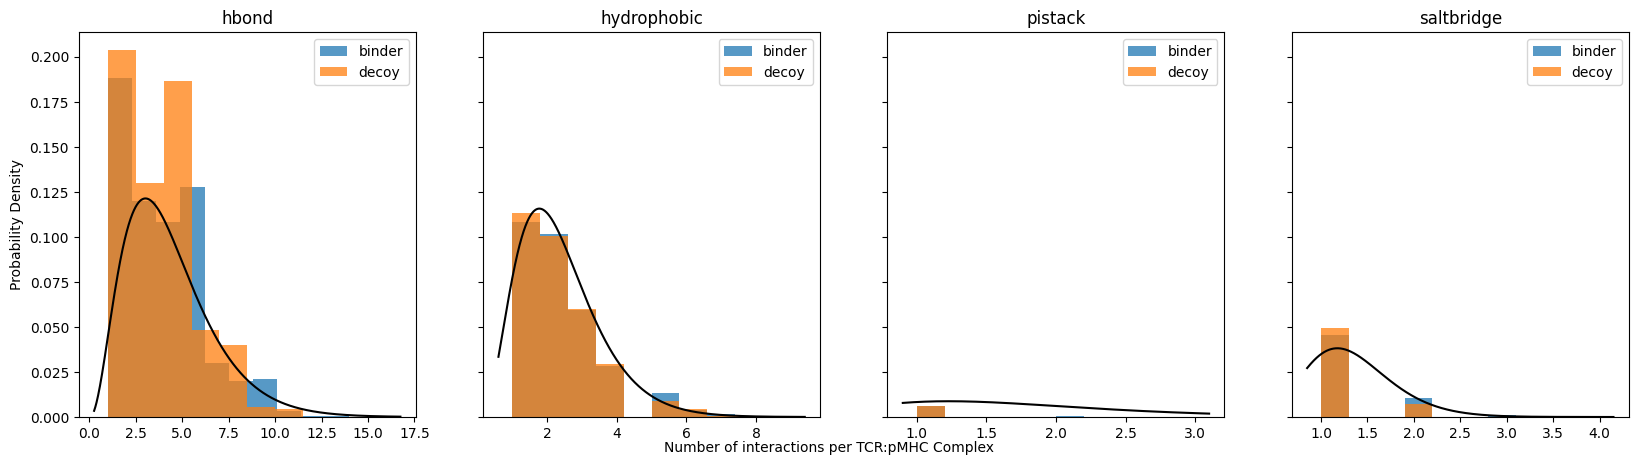

In [40]:
af3_interaction_types = af3_interactions.value_counts(
    ['name', 'seed', 'sample', 'type', 'label', 'type_interaction']
).reset_index()

total_count = af3_interaction_types['count'].sum()

number_of_interaction_types = len(interaction_types_parameters)

fig, axes = plt.subplots(1, number_of_interaction_types, figsize=(5 * number_of_interaction_types, 5), sharey=True)

for i, (interaction_type, group) in enumerate(af3_interaction_types.groupby('type_interaction')):
    group_count = group['count'].sum()

    weight = group_count / total_count

    for complex_type, sub_group in group.groupby('type'):
        counts, bins = np.histogram(sub_group['count'])
        probabilities = (counts / counts.sum()) * weight

        axes[i].stairs(
            probabilities,
            bins,
            fill=True,
            alpha=0.75,
            label=complex_type,
        )

    x = np.linspace(*axes[i].get_xlim(), 1000)
    y = (
        scipy.stats.gamma.pdf(
            x,
            a=interaction_types_parameters[interaction_type]['a'],
            loc=interaction_types_parameters[interaction_type]['loc'],
            scale=interaction_types_parameters[interaction_type]['scale'],
        )
        * interaction_types_parameters[interaction_type]['weight']
    )

    axes[i].plot(x, y, '-', color='black')

    axes[i].set_title(interaction_type)
    axes[i].legend()

    print(interaction_type, 'ROC-AUC:', sklearn.metrics.roc_auc_score(group['label'], group['count']))

axes[0].set_ylabel('Probability Density')
fig.text(0.5, 0.04, 'Number of interactions per TCR:pMHC Complex', ha='center')

plt.show()

In [41]:
index = pd.MultiIndex.from_frame(structure_scores[['name', 'seed', 'sample']])
probabilities = pd.Series(np.zeros(len(index)), index=index)
probabilities.name = 'interaction_type_probability'
for interaction_type, params in interaction_types_parameters.items():
    interaction_type_counts = af3_interaction_types[
        af3_interaction_types['type_interaction'] == interaction_type
    ].set_index(['name', 'seed', 'sample'])['count']

    interaction_type_probabilities = interaction_type_counts.apply(
        lambda counts, params=params: (
            params['weight'] * scipy.stats.gamma.pdf(counts, a=params['a'], loc=params['loc'], scale=params['scale'])
        ),
    )
    interaction_type_probabilities.name = 'interaction_type_probability'

    probabilities = probabilities.add(interaction_type_probabilities, fill_value=0.0)

structure_scores = structure_scores.merge(probabilities.reset_index(), how='left', on=['name', 'seed', 'sample'])

In [42]:
tcr_pmhc_sc_and_bsa = pd.read_csv('../data/processed/tcr_pmhc_sc_and_bsa.csv', index_col='name')

In [43]:
predicted_sc_and_bsa = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_sc_and_bsa_1500.csv')

In [44]:
predicted_sc_and_bsa = predicted_sc_and_bsa.merge(entries, how='left', left_on='name', right_on='index')

mu=0.6789347772816737, sigma=0.11286066788640256


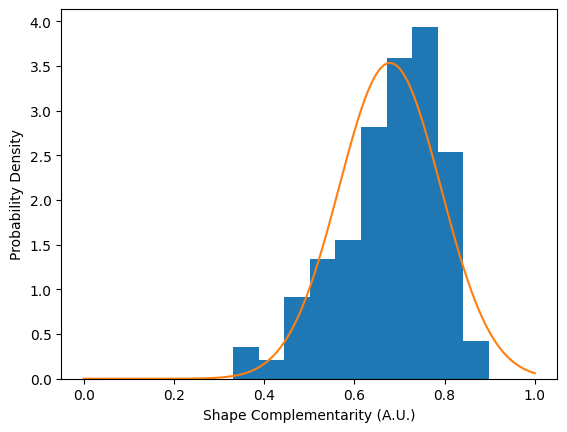

In [45]:
loc, scale = scipy.stats.norm.fit(tcr_pmhc_sc_and_bsa['sc'])
print(f'mu={loc}, sigma={scale}')
sc_score = scipy.stats.norm(loc=loc, scale=scale)

ax = tcr_pmhc_sc_and_bsa['sc'].plot.hist(density=True)

x = np.linspace(0, 1, 1000)
y = sc_score.pdf(x)

ax.plot(x, y, '-')

ax.set_xlabel('Shape Complementarity (A.U.)')
ax.set_ylabel('Probability Density')

plt.show()

In [46]:
predicted_sc_and_bsa['sc_probability'] = predicted_sc_and_bsa['sc'].apply(sc_score.pdf)

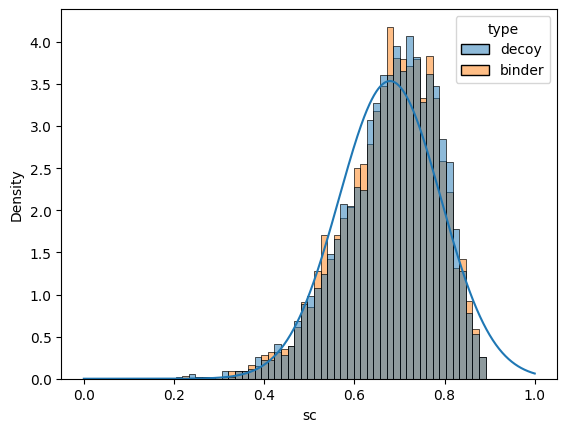

In [47]:
x = np.linspace(0, 1, 1000)
plt.plot(x, sc_score.pdf(x))

sns.histplot(predicted_sc_and_bsa, x='sc', hue='type', stat='density', common_norm=False)

plt.show()

mu=1864.6291050366613, sigma=258.0470155183349


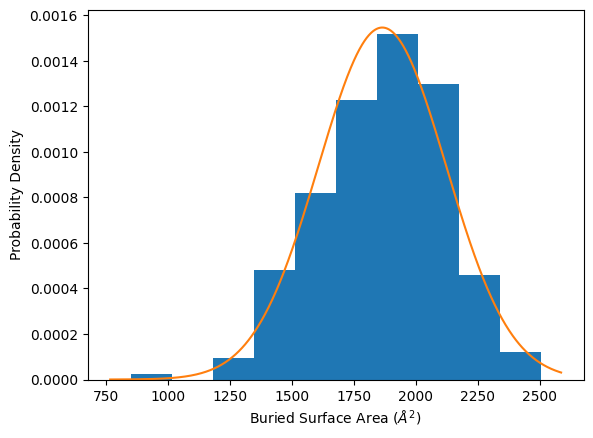

In [48]:
loc, scale = scipy.stats.norm.fit(tcr_pmhc_sc_and_bsa['bsa'])
print(f'mu={loc}, sigma={scale}')
bsa_score = scipy.stats.norm(loc=loc, scale=scale)

ax = tcr_pmhc_sc_and_bsa['bsa'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = bsa_score.pdf(x)

ax.plot(x, y, '-')

ax.set_xlabel(r'Buried Surface Area ($\AA^2$)')
ax.set_ylabel('Probability Density')

plt.show()

In [49]:
predicted_sc_and_bsa['bsa_probability'] = predicted_sc_and_bsa['bsa'].apply(bsa_score.pdf)

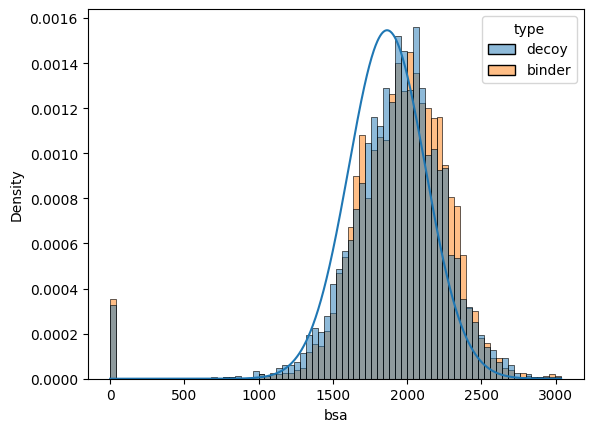

In [50]:
x = np.linspace(predicted_sc_and_bsa['bsa'].min(), predicted_sc_and_bsa['bsa'].max(), 1000)
plt.plot(x, bsa_score.pdf(x))

sns.histplot(predicted_sc_and_bsa, x='bsa', hue='type', stat='density', common_norm=False)

plt.show()

In [51]:
structure_scores = structure_scores.merge(
    predicted_sc_and_bsa[['name', 'seed', 'sample', 'sc_probability', 'bsa_probability']],
    how='left',
    on=['name', 'seed', 'sample'],
)

In [52]:
structure_probability_names = [
    'scanning_angle_probability',
    'pitch_angle_probability',
    'tilt_angle_probability',
    'roll_angle_probability',
    'x_score_probability',
    'y_score_probability',
    'z_score_probability',
    'contact_map_probability',
    'num_interactions_probability',
    'interaction_type_probability',
    'sc_probability',
    'bsa_probability',
]

In [53]:
structure_scores_excluded = structure_scores[structure_scores.isna().any(axis=1)]
print(len(structure_scores_excluded), 'complexes excluded for not binding correctly')

125 complexes excluded for not binding correctly


In [54]:
structure_scores_excluded.groupby('index').size().value_counts().sort_index()

1    37
2     9
3     2
4     6
5     8
Name: count, dtype: int64

In [55]:
structure_scores_excluded['type'].value_counts()

type
decoy     63
binder    62
Name: count, dtype: int64

In [56]:
print('Decoys with malformed complexes:')
(
    structure_scores_excluded[structure_scores_excluded['type'] == 'decoy']
    .groupby('index')
    .size()
    .value_counts()
    .sort_index()
)

Decoys with malformed complexes:


1    20
2     4
3     1
4     3
5     4
Name: count, dtype: int64

In [57]:
structure_scores = structure_scores.dropna().copy()

In [58]:
with np.errstate(divide='ignore'):
    structure_scores['log_probability'] = structure_scores[structure_probability_names].apply(
        lambda row: np.sum(np.log(row)), axis=1
    )

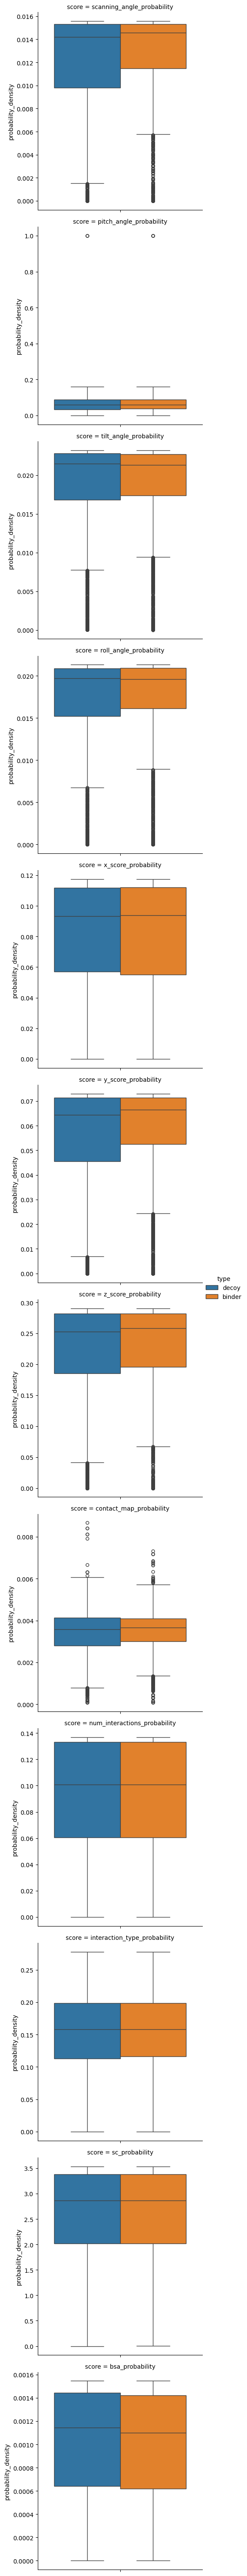

In [59]:
score_probabilities = structure_scores.melt(
    id_vars=['type', 'label'],
    value_vars=structure_probability_names,
    var_name='score',
    value_name='probability_density',
)
sns.catplot(score_probabilities, row='score', y='probability_density', hue='type', sharey=False, kind='box')

In [60]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability_density']))

bsa_probability
0.48380890059286685
contact_map_probability
0.5239544227328592
interaction_type_probability
0.5060952417093064
num_interactions_probability
0.5094997255409315
pitch_angle_probability
0.5133150154703134
roll_angle_probability
0.5131019640443912
sc_probability
0.5018657259751239
scanning_angle_probability
0.5293863515888326
tilt_angle_probability
0.4913107817994513
x_score_probability
0.5006135616315047
y_score_probability
0.5340894783630356
z_score_probability
0.5199538802864259


## Feature processing

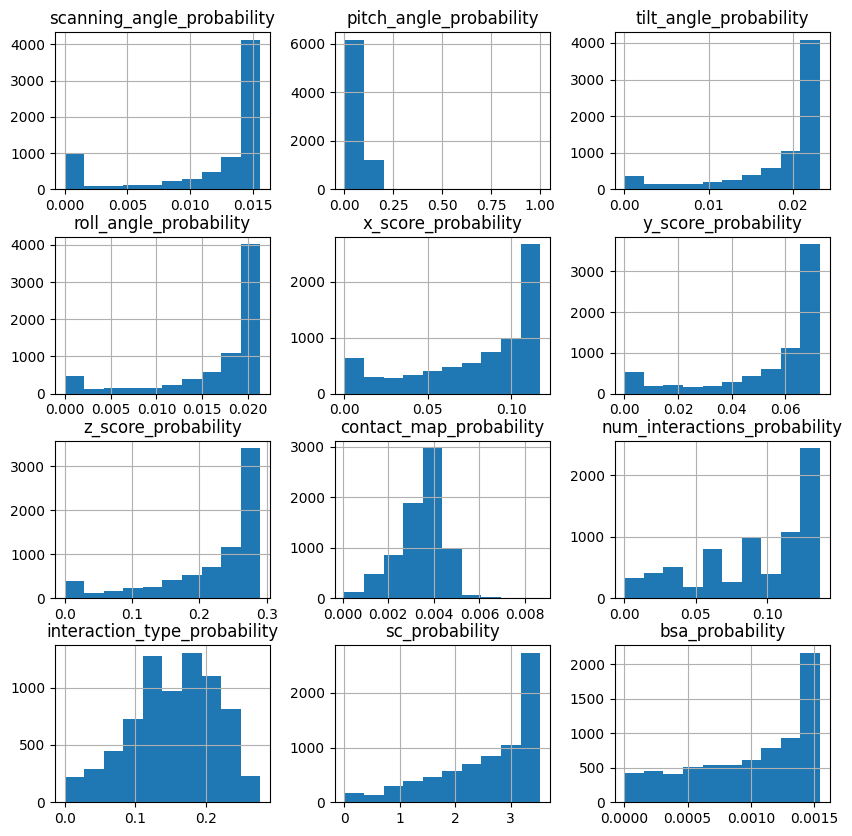

In [61]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

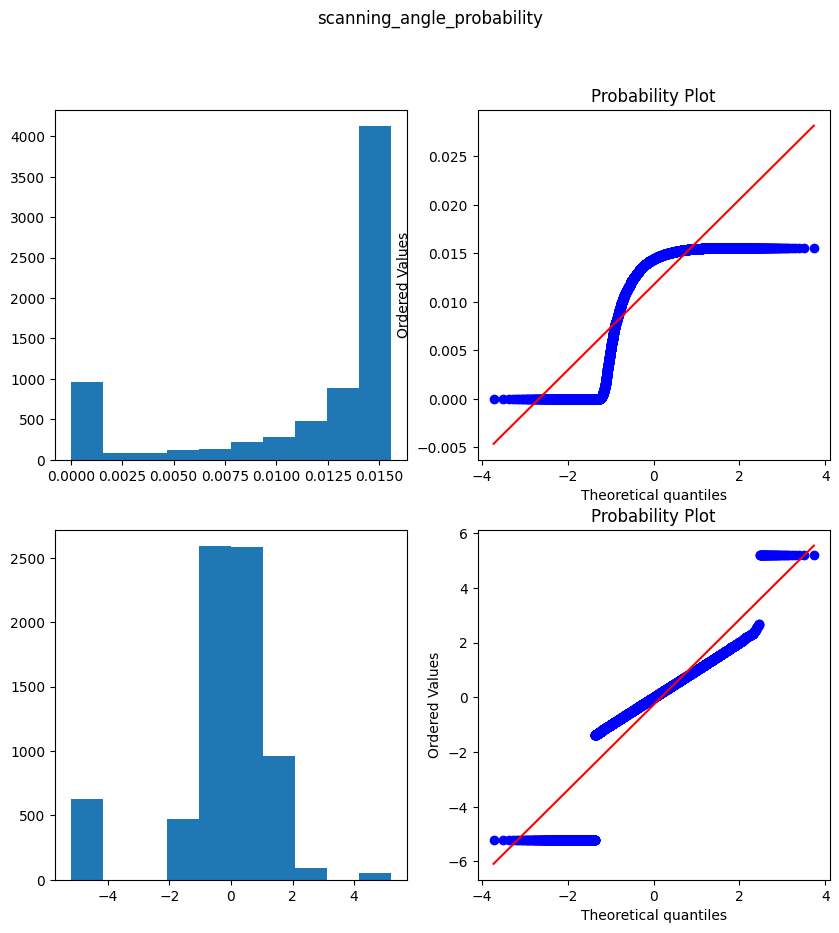

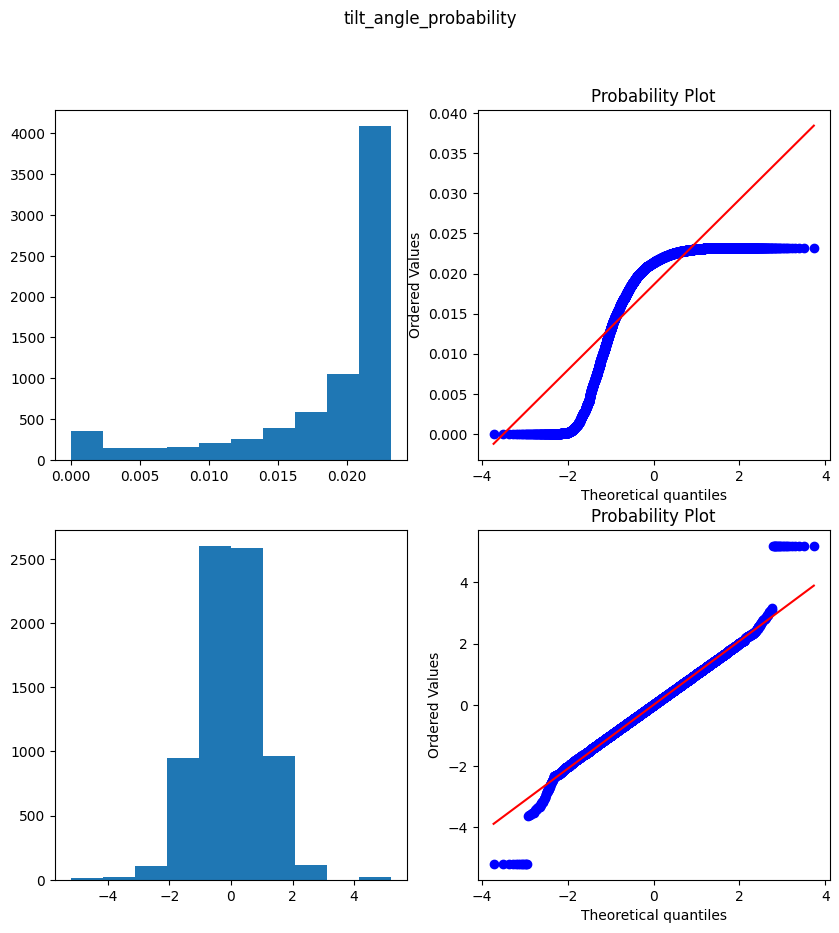

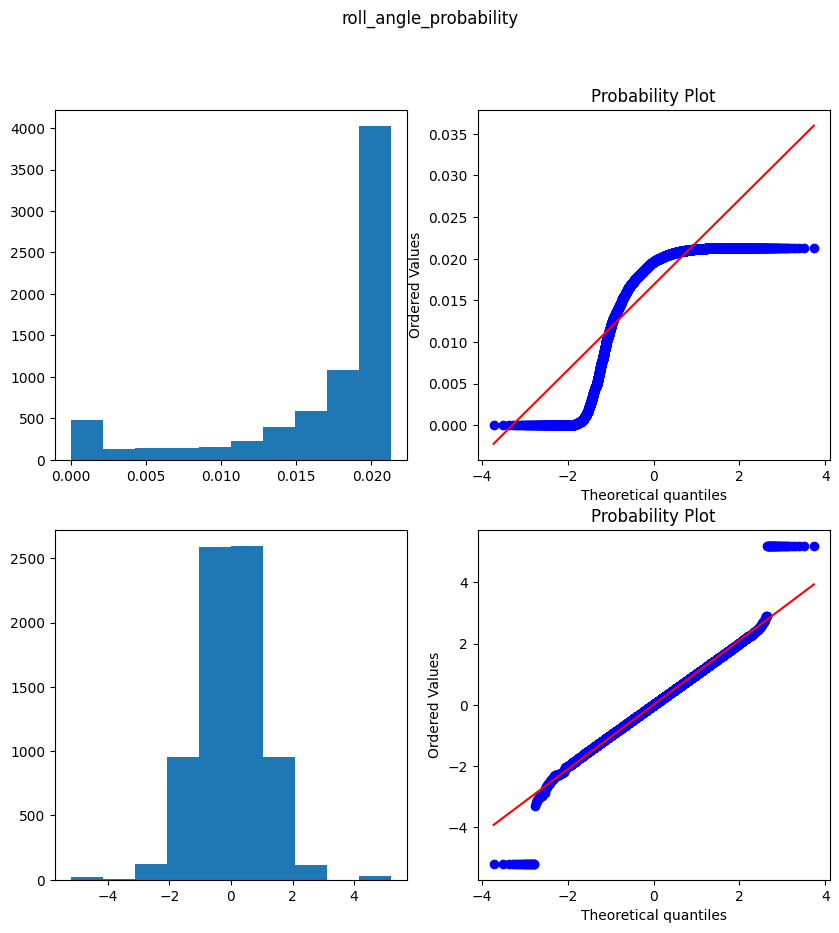

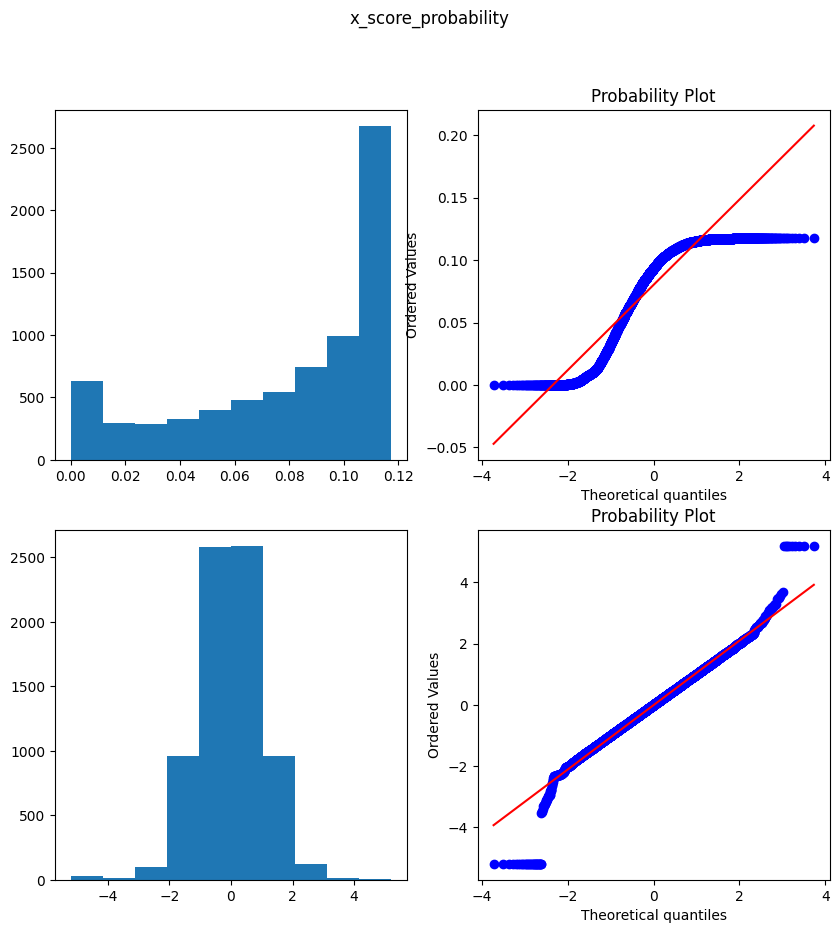

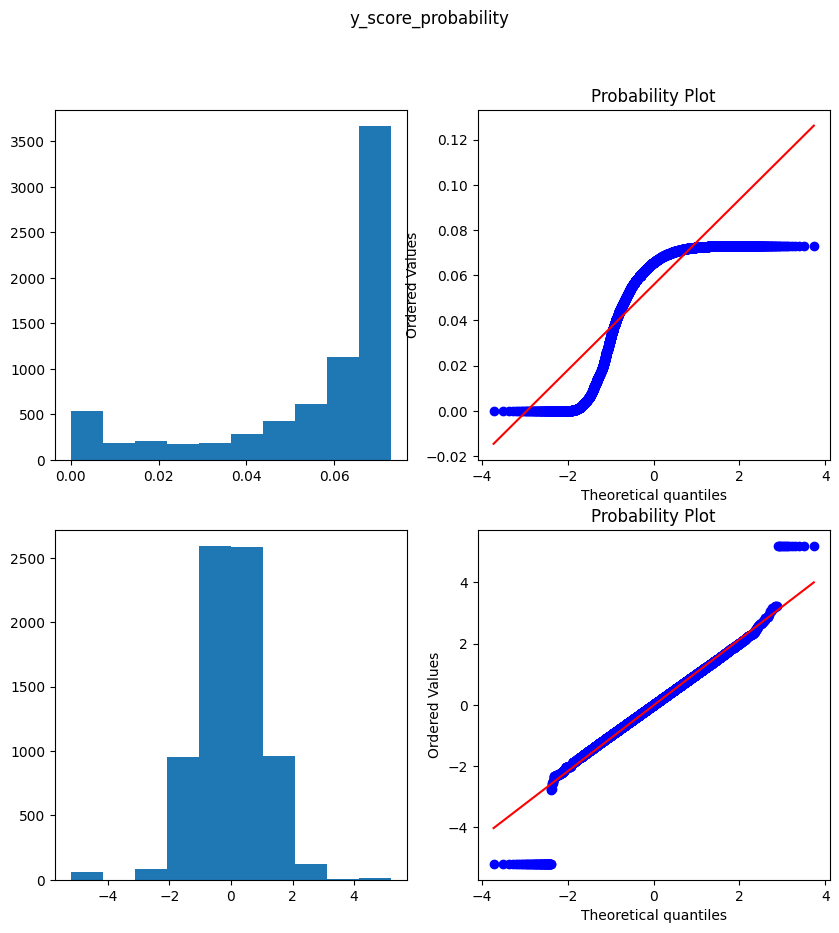

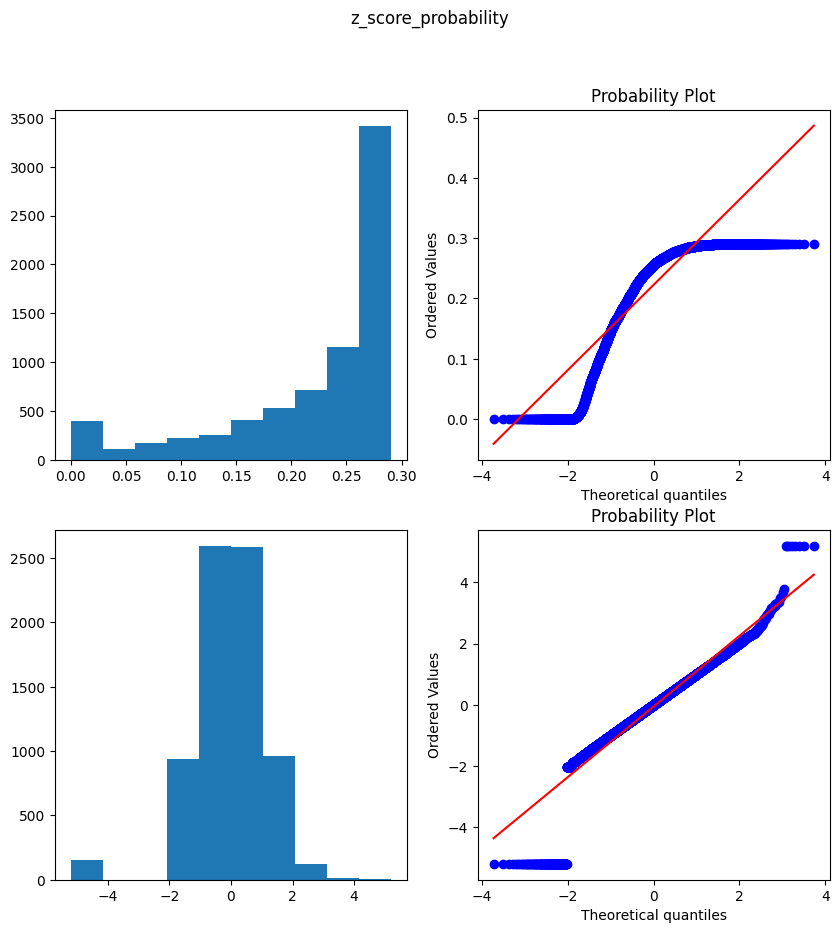

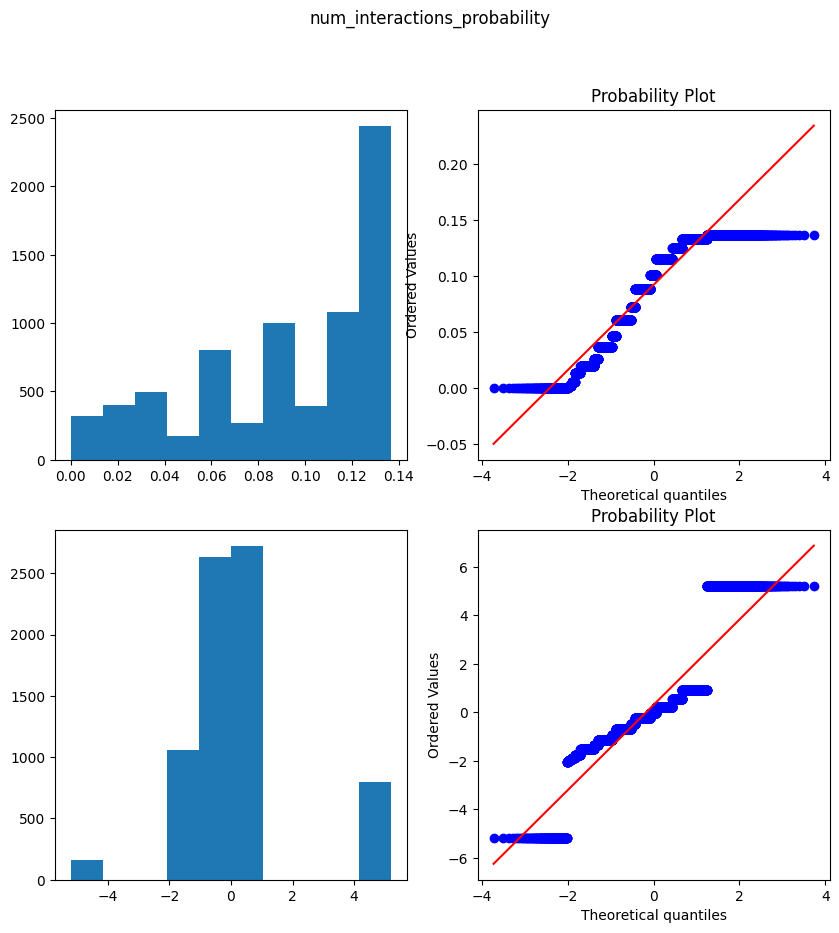

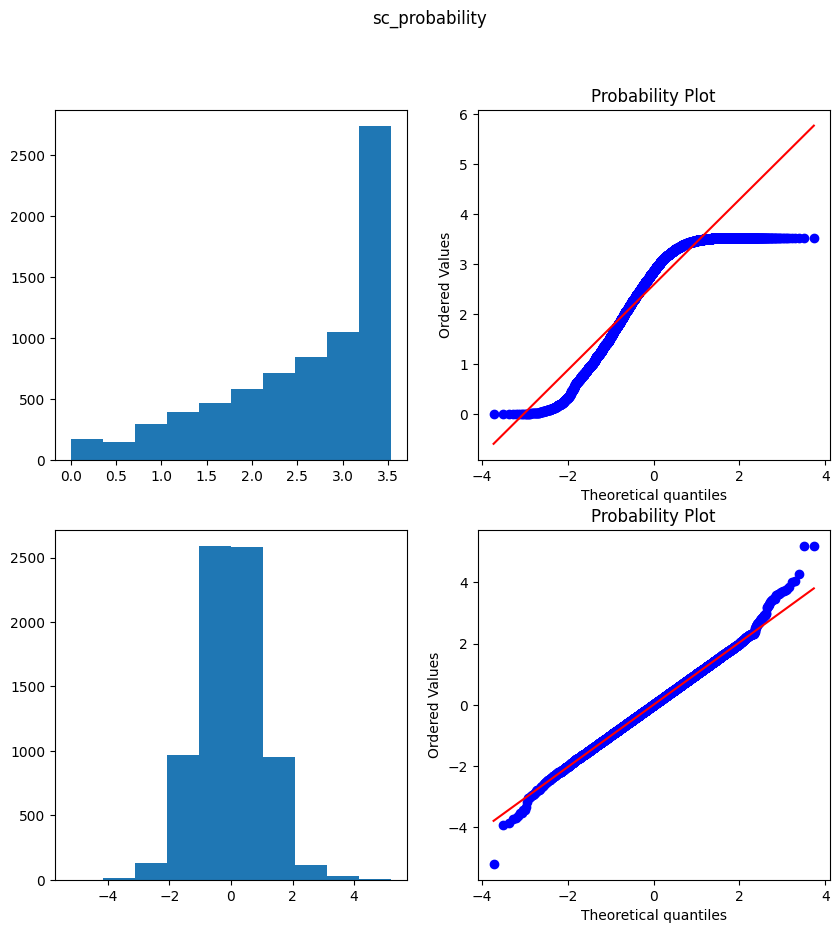

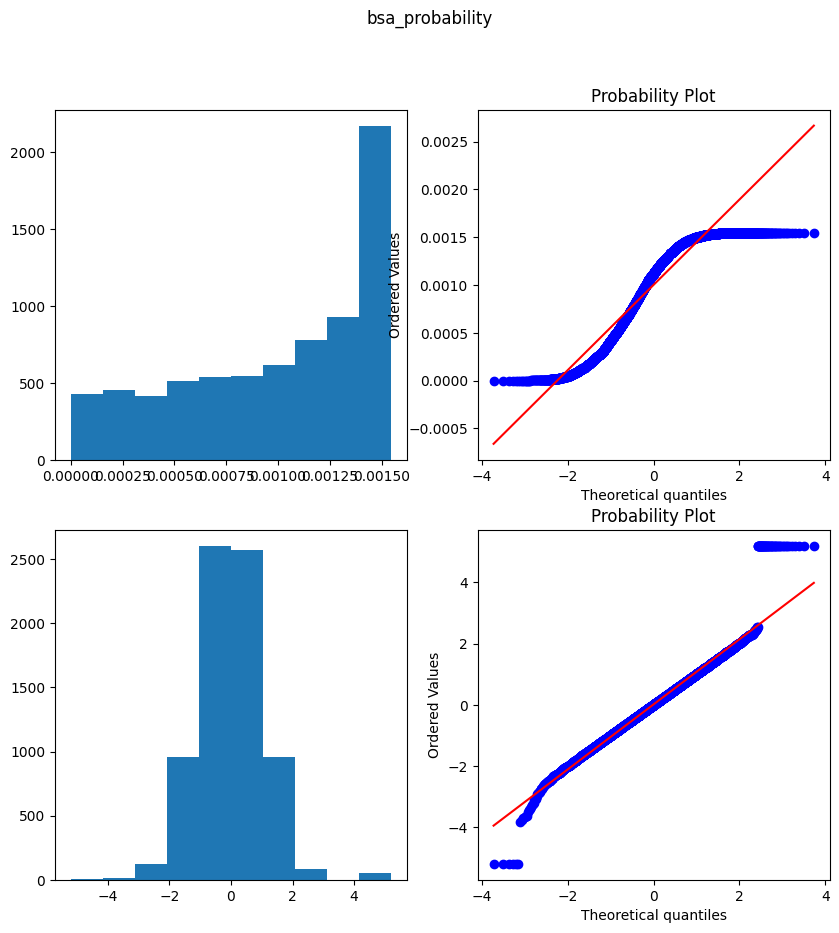

In [62]:
for selected_column in (
    'scanning_angle_probability',
    'tilt_angle_probability',
    'roll_angle_probability',
    'x_score_probability',
    'y_score_probability',
    'z_score_probability',
    'num_interactions_probability',
    'sc_probability',
    'bsa_probability',
):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    fig.suptitle(selected_column)
    x = structure_scores[selected_column].to_numpy()

    qt = sklearn.preprocessing.QuantileTransformer(output_distribution='normal', n_quantiles=100)
    x_transformed = qt.fit_transform(x.reshape(-1, 1)).squeeze()

    structure_scores[selected_column + '_transformed'] = x_transformed

    axes[0, 0].hist(x)
    scipy.stats.probplot(x, dist=scipy.stats.norm, plot=axes[0, 1])

    axes[1, 0].hist(x_transformed)
    scipy.stats.probplot(x_transformed, dist=scipy.stats.norm, plot=axes[1, 1])

    structure_probability_names = [
        column if column != selected_column else selected_column + '_transformed'
        for column in structure_probability_names
    ]

    plt.show()

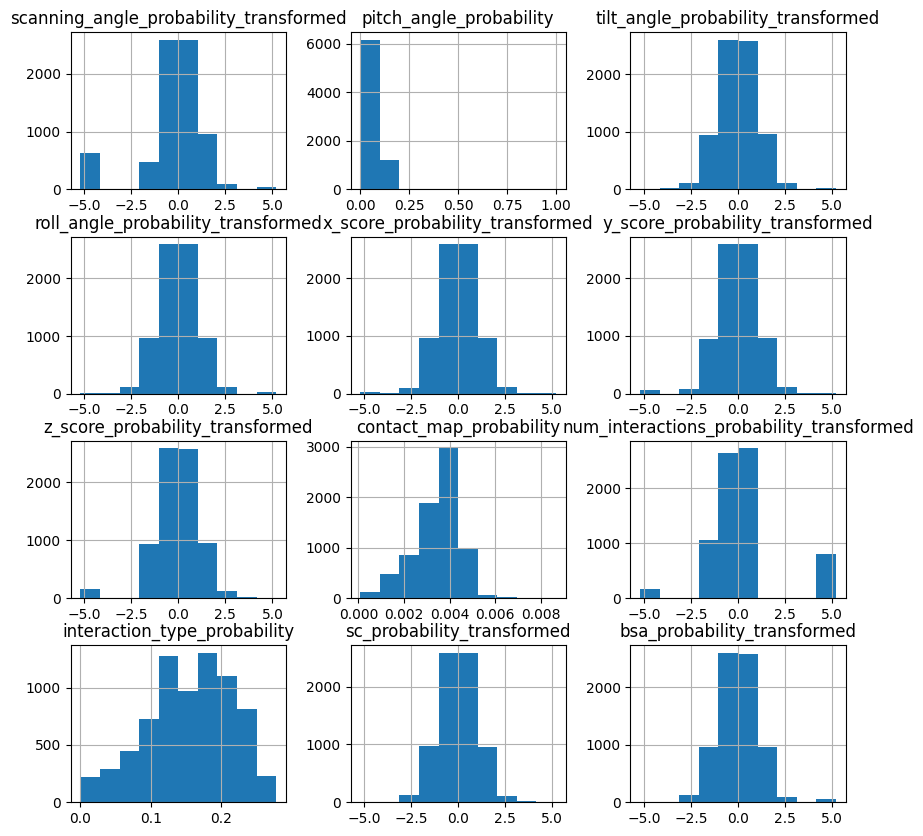

In [63]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

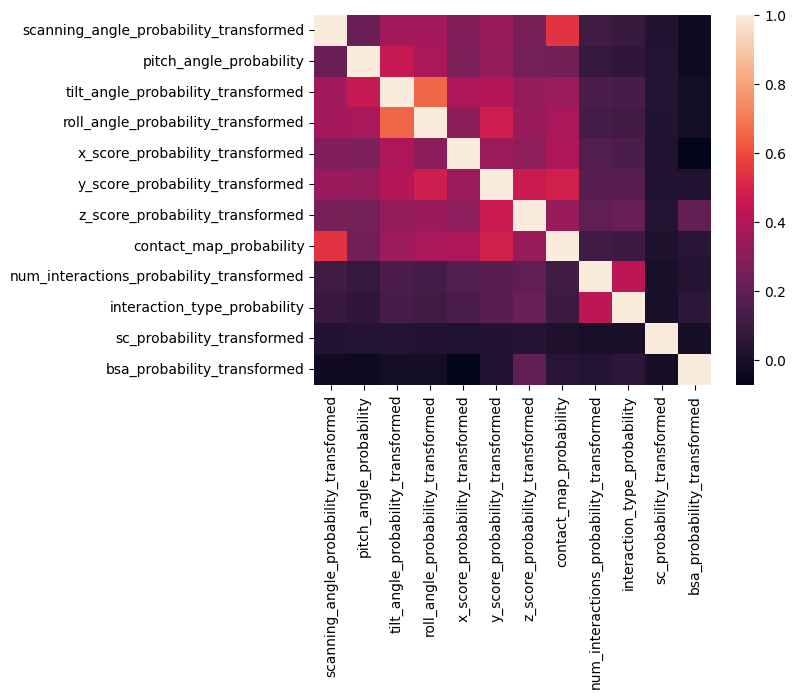

In [64]:
sns.heatmap(structure_scores[structure_probability_names].corr())
plt.show()

In [65]:
structure_probability_names = [
    column
    for column in structure_probability_names
    if column not in {'scanning_angle_probability_transformed', 'roll_angle_probability_transformed'}
]

In [66]:
def drop_constant_confidence(df: pd.DataFrame, confidence_pattern: str = 'pae|ptm|plddt|ipsae') -> pd.DataFrame:
    def check_constant(column: pd.Series) -> bool:
        return (column == column.iloc[0]).all()

    confidence_pattern = re.compile(confidence_pattern)

    return df[
        [column for column in df.columns if not check_constant(df[column]) or not re.search(confidence_pattern, column)]
    ]


structure_scores = drop_constant_confidence(structure_scores)

## Regression analysis

In [67]:
regression_fits = defaultdict(list)

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

groups = structure_scores['index']


def calculate_mixed_r_squared(reg: MixedLMResults) -> tuple[float, float]:
    var_fixed = np.var(np.dot(reg.model.exog, reg.fe_params), ddof=1)
    var_random = reg.cov_re.iloc[0, 0]
    var_resid = reg.scale

    r2_marginal = var_fixed / (var_fixed + var_random + var_resid)
    r2_conditional = (var_fixed + var_random) / (var_fixed + var_random + var_resid)

    return r2_marginal, r2_conditional


# PAE
pae_confidence_columns = sorted(structure_scores.filter(regex='pae').columns.tolist())
for confidence_column in pae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.MixedLM(y, X, groups)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            reg = model.fit()

    except ConvergenceWarning:
        print('Skipping', confidence_column)
        continue

    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)
    r_squared_marginal, r_squared_conditional = calculate_mixed_r_squared(reg)

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('PAE')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared_marginal'].append(r_squared_marginal)
    regression_fits['r_squared_conditional'].append(r_squared_conditional)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# (i)PTM
ptm_confidence_columns = sorted(structure_scores.filter(regex='ptm').columns.tolist())
for confidence_column in ptm_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.MixedLM(y, X, groups)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            reg = model.fit()

    except ConvergenceWarning:
        print('Skipping', confidence_column)
        continue

    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)
    r_squared_marginal, r_squared_conditional = calculate_mixed_r_squared(reg)

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('(i)PTM')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared_marginal'].append(r_squared_marginal)
    regression_fits['r_squared_conditional'].append(r_squared_conditional)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# pLDDT
plddt_confidence_columns = sorted(structure_scores.filter(regex='plddt').columns.tolist())
for confidence_column in plddt_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.MixedLM(y, X, groups)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            reg = model.fit()

    except ConvergenceWarning:
        print('Skipping', confidence_column)
        continue

    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)
    r_squared_marginal, r_squared_conditional = calculate_mixed_r_squared(reg)

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('pLDDT')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared_marginal'].append(r_squared_marginal)
    regression_fits['r_squared_conditional'].append(r_squared_conditional)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# IPSAE
ipsae_confidence_columns = sorted(structure_scores.filter(regex='ipsae').columns.tolist())
for confidence_column in ipsae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.MixedLM(y, X, groups)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            reg = model.fit()

    except ConvergenceWarning:
        print('Skipping', confidence_column)
        continue

    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)
    r_squared_marginal, r_squared_conditional = calculate_mixed_r_squared(reg)

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('IPSAE')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared_marginal'].append(r_squared_marginal)
    regression_fits['r_squared_conditional'].append(r_squared_conditional)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

regression_fits = pd.DataFrame(regression_fits)
regression_fits = regression_fits.set_index('confidence_score')
regression_fits = regression_fits.sort_values('r_squared_marginal', ascending=False)

Skipping mhc_chain_1_mhc_chain_2_pae_min
Skipping mhc_chain_2_mhc_chain_1_pae_min
Skipping mhc_chain_1_mhc_chain_2_iptm
Skipping mhc_chain_1_peptide_iptm
Skipping mhc_chain_1_ptm
Skipping mhc_chain_2_iptm
Skipping mhc_chain_2_peptide_iptm
Skipping mhc_chain_2_ptm
Skipping peptide_ptm
Skipping ptm
Skipping tcr_alpha_chain_ptm
Skipping tcr_alpha_chain_tcr_beta_chain_iptm
Skipping tcr_beta_chain_ptm
Skipping alpha_chain_antigen_chain_ipsae
Skipping alpha_chain_beta_chain_ipsae
Skipping alpha_chain_mhc_chain2_ipsae
Skipping antigen_chain_mhc_chain1_ipsae
Skipping antigen_chain_mhc_chain2_ipsae
Skipping beta_chain_alpha_chain_ipsae
Skipping beta_chain_antigen_chain_ipsae
Skipping beta_chain_mhc_chain2_ipsae
Skipping mhc_chain1_antigen_chain_ipsae
Skipping mhc_chain1_mhc_chain2_ipsae
Skipping mhc_chain2_antigen_chain_ipsae
Skipping mhc_chain2_mhc_chain1_ipsae


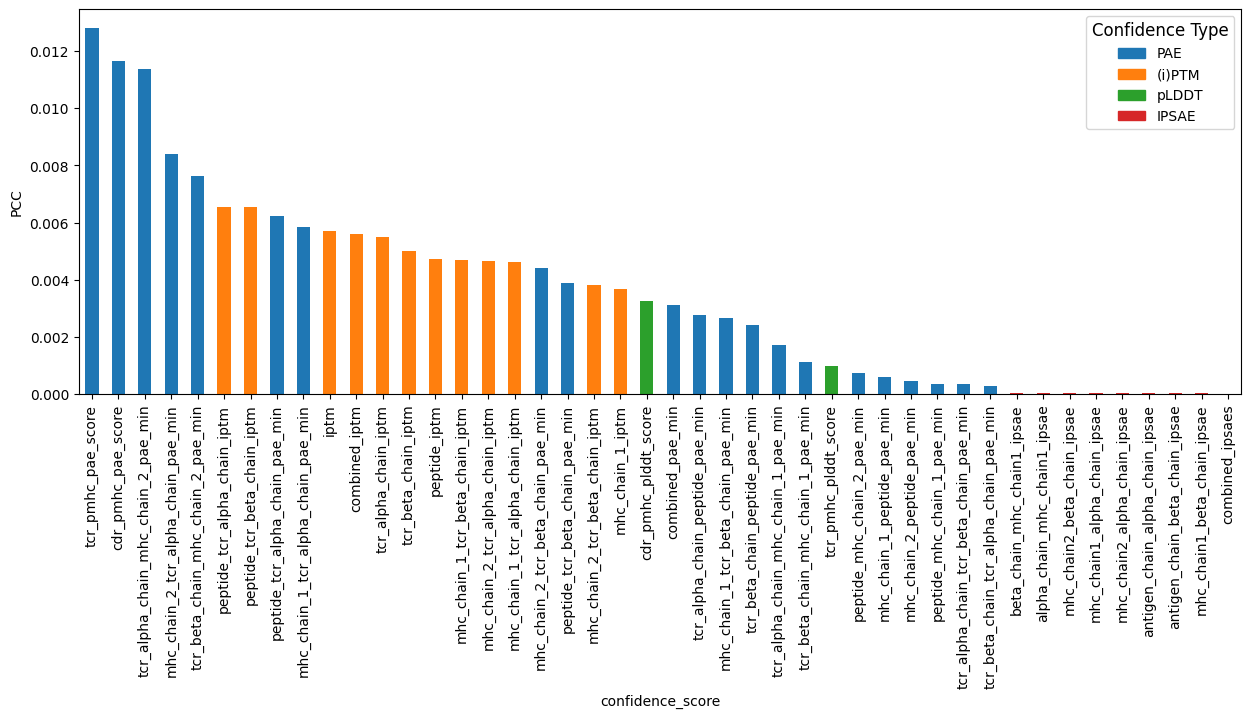

In [68]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
confidence_types = regression_fits['confidence_type'].unique()
colour_map = {c: default_colors[i % len(default_colors)] for i, c in enumerate(confidence_types)}
colours = regression_fits['confidence_type'].map(colour_map)

ax = regression_fits['r_squared_marginal'].plot.bar(figsize=(15, 5), color=colours)
ax.set_ylabel('PCC')

handles = [
    patches.Patch(color=colour_map[confidence_type], label=confidence_type) for confidence_type in confidence_types
]
ax.legend(handles=handles, title='Confidence Type', title_fontsize=12)

plt.show()

In [69]:
print('cdr_pmhc_pae_score')
print('==============================================================================================')
print(f"R^2 marginal: {regression_fits.loc['cdr_pmhc_pae_score']['r_squared_marginal']:.2e}")
print(f"R^2 conditional: {regression_fits.loc['cdr_pmhc_pae_score']['r_squared_conditional']:.2f}")
print(f"Pearson's correlation: {regression_fits.loc['cdr_pmhc_pae_score']['correlation_coef']:.2f}")
print(regression_fits.loc['cdr_pmhc_pae_score']['reg_summary'])
print('\n\n')

cdr_pmhc_pae_score
R^2 marginal: 1.16e-02
R^2 conditional: 0.98
Pearson's correlation: 0.99
                          Mixed Linear Model Regression Results
Model:                      MixedLM         Dependent Variable:         cdr_pmhc_pae_score
No. Observations:           7375            Method:                     REML              
No. Groups:                 1492            Scale:                      0.6125            
Min. group size:            1               Log-Likelihood:             -12768.9607       
Max. group size:            5               Converged:                  Yes               
Mean group size:            4.9                                                           
------------------------------------------------------------------------------------------
                                          Coef.   Std.Err.    z    P>|z|  [0.025   0.975] 
------------------------------------------------------------------------------------------
const                    

In [70]:
coeficient_columns = ['parameter', 'standard_error', 't_stat', 'probability', 'significant']
coefficients = regression_fits.loc['cdr_pmhc_pae_score'][
    [
        name
        for name in regression_fits.loc['cdr_pmhc_pae_score'].index
        if type(name) is tuple and name[1] in coeficient_columns
    ]
]

coefficients.index = pd.MultiIndex.from_tuples(coefficients.index)

coefficients = coefficients.unstack()  # noqa: PD010 unstack cleaner here
coefficients = coefficients[coeficient_columns]

coefficients.style.format({'probability': '{:.2e}'})

,parameter,standard_error,t_stat,probability,significant
bsa_probability_transformed,-0.011840,0.013452,-0.880140,1.89e-01,False
contact_map_probability,-254.060521,19.765381,-12.853814,1.03e-37,True
interaction_type_probability,-0.509851,0.230552,-2.211435,1.35e-02,True
num_interactions_probability_transformed,-0.017856,0.006346,-2.813947,2.45e-03,True
pitch_angle_probability,-0.621848,0.322466,-1.928415,2.69e-02,True
sc_probability_transformed,0.005110,0.010318,0.495209,6.90e-01,False
tilt_angle_probability_transformed,-0.100749,0.017995,-5.598670,1.12e-08,True
x_score_probability_transformed,-0.010083,0.017986,-0.560593,2.88e-01,False
y_score_probability_transformed,-0.184911,0.017916,-10.320848,4.18e-25,True
z_score_probability_transformed,-0.155777,0.015236,-10.224308,1.12e-24,True


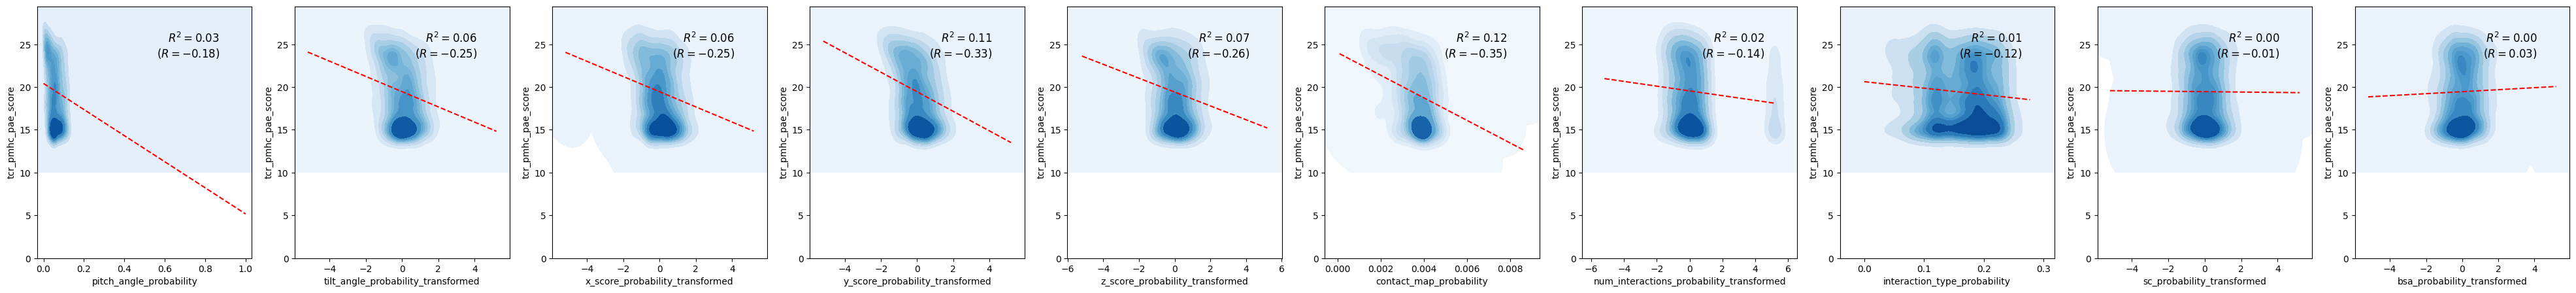

In [71]:
fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

y = structure_scores[regression_fits.iloc[0].name]
y_max = structure_scores[regression_fits.iloc[0].name].max()

for i, column in enumerate(structure_probability_names):
    x = structure_scores[column]
    sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

    reg = scipy.stats.linregress(x, y)
    x = np.linspace(x.min(), x.max())
    y_pred = reg.slope * x + reg.intercept

    axes[i].plot(x, y_pred, 'r--')
    axes[i].text(
        0.85,
        0.90,
        f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
        transform=axes[i].transAxes,
        horizontalalignment='right',
        verticalalignment='top',
        fontsize=12,
    )

    axes[i].set_xlabel(column)
    axes[i].set_ylim(0, y_max)

plt.show()

## Analysing results robustness

### Normalising

In [72]:
data = structure_scores[[*structure_probability_names, 'cdr_pmhc_pae_score']]
data_norm = data.sub(data.mean()).div(data.std())

### Removing outliers using Mahalanobis distance

In [73]:
centre = data_norm.mean(axis=0)
centred_data = data_norm.to_numpy() - centre.to_numpy().reshape(1, -1)

covariance = np.cov(data_norm, rowvar=False)
covariance_inv = np.linalg.inv(covariance)

distances = np.dot(np.dot(centred_data, covariance_inv), centred_data.T).diagonal()

In [74]:
outlier_mask = distances <= scipy.stats.chi2.ppf(0.95, data_norm.shape[1])
data_no_outliers = data_norm.loc[outlier_mask].copy()
data_no_outliers['index'] = structure_scores.loc[outlier_mask, 'index']

In [75]:
def check_constant_column(column: pd.Series) -> bool:
    return (column.iloc[0] == column).all()


contstant_columns_to_drop = [
    column_name for column_name in data_no_outliers.columns if check_constant_column(data_no_outliers[column_name])
]
print('Dropping constant columns', contstant_columns_to_drop)
data_no_outliers = data_no_outliers[
    [column_name for column_name in data_no_outliers.columns if column_name not in contstant_columns_to_drop]
]

no_outliers_structure_columns = [
    column_name for column_name in data_no_outliers.columns if column_name not in ('cdr_pmhc_pae_score', 'index')
]

Dropping constant columns []


In [76]:
X = data_no_outliers[no_outliers_structure_columns]
X = sm.add_constant(X, has_constant='raise')
y = data_no_outliers['cdr_pmhc_pae_score']
groups = data_no_outliers['index']

In [77]:
model = sm.MixedLM(y, X, groups)
reg = model.fit()
pred_y = reg.fittedvalues

with warnings.catch_warnings():
    warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

print(reg.summary())

coefficients_no_outliers = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
coefficients_no_outliers.columns = ['parameter', 'standard_error']

coefficients_no_outliers['t_stat'] = coefficients_no_outliers['parameter'] / coefficients_no_outliers['standard_error']

coefficients_no_outliers['probability'] = coefficients_no_outliers['t_stat'].apply(
    lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
)
coefficients_no_outliers['significant'] = coefficients_no_outliers['probability'] < SIGNIFICANCE_LEVEL

coefficients_no_outliers = coefficients_no_outliers.sort_values('parameter')
coefficients_no_outliers

                       Mixed Linear Model Regression Results
Model:                    MixedLM       Dependent Variable:       cdr_pmhc_pae_score
No. Observations:         6824          Method:                   REML              
No. Groups:               1476          Scale:                    0.0162            
Min. group size:          1             Log-Likelihood:           241.3503          
Max. group size:          5             Converged:                Yes               
Mean group size:          4.6                                                       
------------------------------------------------------------------------------------
                                         Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------
const                                     0.001    0.025   0.049 0.961 -0.048  0.050
pitch_angle_probability                  -0.019    0.005  -3.743 0.000 -0.030 -0.009
tilt

,parameter,standard_error,t_stat,probability,significant
contact_map_probability,-0.051514,0.003984,-12.930416,4.209590e-38,True
pitch_angle_probability,-0.019376,0.005177,-3.743112,9.162564e-05,True
y_score_probability_transformed,-0.018349,0.004045,-4.536587,2.907581e-06,True
tilt_angle_probability_transformed,-0.015809,0.004097,-3.859048,5.744047e-05,True
z_score_probability_transformed,-0.008160,0.003927,-2.078054,1.887087e-02,True
num_interactions_probability_transformed,-0.006161,0.002268,-2.716033,3.311803e-03,True
x_score_probability_transformed,-0.001198,0.003916,-0.306029,3.797959e-01,False
sc_probability_transformed,0.000523,0.001847,0.283094,6.114435e-01,False
interaction_type_probability,0.001698,0.002429,0.698920,7.576871e-01,False
bsa_probability_transformed,0.004872,0.003018,1.614603,9.467785e-01,False


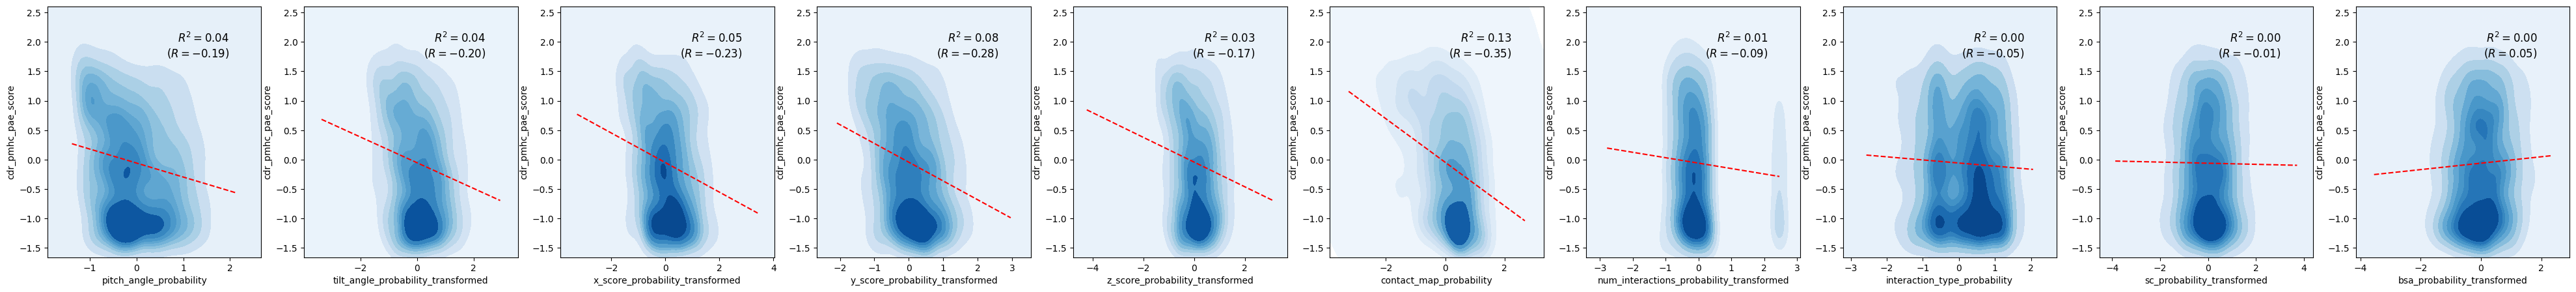

In [78]:
fig, axes = plt.subplots(1, len(no_outliers_structure_columns), figsize=(5 * len(no_outliers_structure_columns), 5))

y_max = y.max()
y_min = y.min()

for i, column in enumerate(no_outliers_structure_columns):
    x = X[column]
    sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i], warn_singular=False)

    try:
        reg = scipy.stats.linregress(x, y)

    except ValueError:
        pass

    else:
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

    axes[i].set_xlabel(column)
    axes[i].set_ylim(y_min, y_max)

plt.show()

### Bootstrapping results

In [79]:
bootstrap_fits = defaultdict(list)

num_samples = 100
sample_size = 1_000
rng = np.random.default_rng(123)

for _ in range(num_samples):
    sample = data_no_outliers.sample(sample_size, random_state=rng)

    X = sample[no_outliers_structure_columns]
    X = sm.add_constant(X)
    y = sample['cdr_pmhc_pae_score']
    groups = sample['index']

    model = sm.MixedLM(y, X, groups)
    reg = model.fit()
    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    bootstrap_fits['correlation_coef'].append(corr_coef)
    bootstrap_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.fe_params[1:], reg.bse_fe[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        bootstrap_fits[key].append(value)

bootstrap_fits = pd.DataFrame(bootstrap_fits)

In [80]:
bootstrap_significance = bootstrap_fits[
    [
        column_name
        for column_name in bootstrap_fits.columns
        if type(column_name) is tuple and column_name[1] == 'significant'
    ]
]

bootstrap_significance.columns = [column_name[0] for column_name in bootstrap_significance.columns]
bootstrap_significance = bootstrap_significance.melt(
    value_vars=bootstrap_significance.columns, var_name='property', value_name='significant'
)

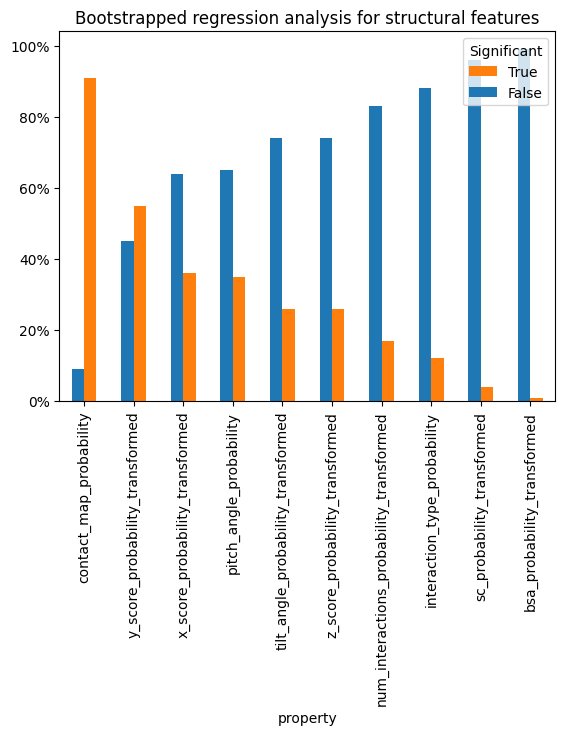

In [81]:
ax = (
    bootstrap_significance.map(str)
    .value_counts()
    .reset_index()
    .pivot_table(index='property', columns='significant', values='count')
    .fillna(0)
    .map(int)
    .sort_values('True', ascending=False)
    .plot.bar()
)

ax.yaxis.set_major_formatter(PercentFormatter())

handles, labels = ax.get_legend_handles_labels()
labels, handles = zip(*sorted(zip(labels, handles, strict=True), key=lambda t: t[0], reverse=True), strict=True)
ax.legend(handles, labels, title='Significant', loc='upper right')

ax.set_title('Bootstrapped regression analysis for structural features')

plt.show()

In [82]:
bootstrap_parameters = bootstrap_fits[
    [column for column in bootstrap_fits.columns if isinstance(column, tuple) and column[1] == 'parameter']
]
bootstrap_parameters.columns = [column[0] for column in bootstrap_parameters]
bootstrap_parameters = bootstrap_parameters.melt(
    value_vars=bootstrap_parameters, var_name='feature', value_name='parameter'
)

[]

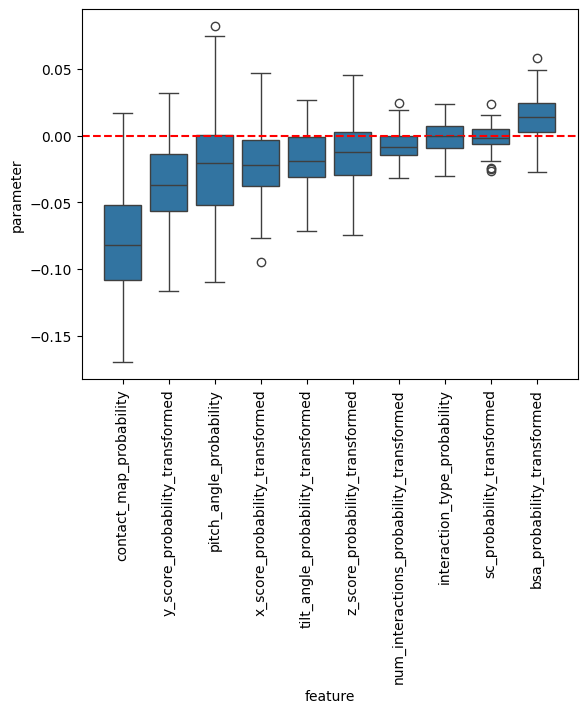

In [83]:
order = bootstrap_parameters.groupby('feature')['parameter'].mean().sort_values().index.tolist()

ax = sns.boxplot(
    bootstrap_parameters.sort_values('feature', key=lambda s: s.map(order.index)), x='feature', y='parameter'
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

ax.axhline(0, color='red', linestyle='dashed')

plt.plot()

In [84]:
bootstrap_parameters_agg = bootstrap_parameters.groupby('feature')['parameter'].agg(['mean', 'sem']).sort_values('mean')

parameter_analysis = pd.concat([coefficients_no_outliers, bootstrap_parameters_agg], axis=1)
parameter_analysis['ci'] = parameter_analysis.apply(
    lambda row: (row['parameter'] - row['sem'], row['parameter'] + row['sem']), axis=1
)

In [85]:
def assign_colour(parameter: float, ci: tuple[float, float]) -> str:
    if parameter < 0 and ci[1] < 0:
        return 'green'

    if parameter > 0 and ci[1] > 0:
        return 'red'

    return 'yellow'


colours = parameter_analysis.apply(lambda row: assign_colour(row['parameter'], row['ci']), axis=1)

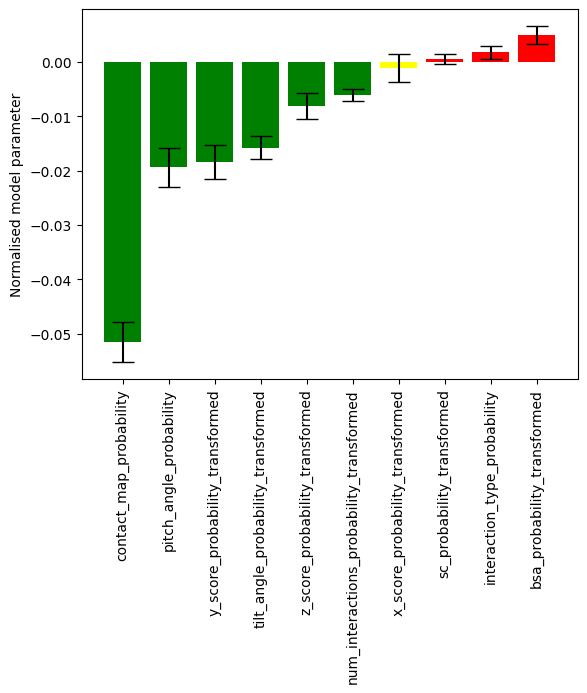

In [86]:
fig, ax = plt.subplots(1, 1)

ax.bar(parameter_analysis.index, parameter_analysis['parameter'], color=colours)

ax.errorbar(
    parameter_analysis.index,
    parameter_analysis['parameter'],
    parameter_analysis['sem'],
    fmt='none',
    color='black',
    capsize=8,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

ax.set_ylabel('Normalised model parameter')

plt.show()